In [ ]:
!pip install -q ultralytics onnx onnxruntime optimum-executorch transformers accelerate huggingface_hub psutil opencv-python-headless

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import random
from pathlib import Path
import cv2
import numpy as np
from ultralytics import YOLO

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
DATASET_DIR = Path("pcb_dataset")

PCB_CLASSES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper",
]

def generate_pcb_frame(seed: int, force_class: int = None):
    rng = random.Random(seed)
    img = np.full((640, 640, 3), (34, 92, 34), dtype=np.uint8)  # PCB solder mask

    # Draw copper tracks & drilled pads
    for y in range(80, 580, 60):
        cv2.line(img, (40, y), (600, y), (45, 165, 195), 6)
        for px in (40, 600):
            cv2.circle(img, (px, y), 10, (70, 200, 225), -1)
            cv2.circle(img, (px, y), 4, (20, 30, 20), -1)

    labels = []
    if force_class == -1:  # Clean defect-free board
        return img, labels

    num_defects = 1 if force_class is not None else rng.randint(1, 3)
    for _ in range(num_defects):
        cid = force_class if force_class is not None else rng.randint(0, len(PCB_CLASSES) - 1)
        cname = PCB_CLASSES[cid]
        row_y = rng.choice(list(range(80, 580, 60)))
        cx = rng.randint(110, 530)
        bw, bh = 38, 38

        if cname == "open_circuit":
            cv2.rectangle(img, (cx - 11, row_y - 6), (cx + 11, row_y + 6), (34, 92, 34), -1)
        elif cname == "short":
            y2 = min(560, row_y + 60)
            cv2.line(img, (cx, row_y), (cx, y2), (65, 195, 220), 6)
            row_y = (row_y + y2) // 2
            bh = 70
        elif cname == "mouse_bite":
            cv2.circle(img, (cx, row_y - 4), 6, (34, 92, 34), -1)
        elif cname == "spur":
            cv2.line(img, (cx, row_y), (cx + 13, row_y - 17), (65, 195, 220), 4)
        elif cname == "spurious_copper":
            row_y = min(560, row_y + 26)
            cv2.circle(img, (cx, row_y), 9, (65, 195, 220), -1)
        elif cname == "missing_hole":
            cx = rng.choice([40, 600])
            cv2.circle(img, (cx, row_y), 8, (70, 200, 225), -1)

        labels.append((cid, cx / 640.0, row_y / 640.0, bw / 640.0, bh / 640.0))
    return img, labels

for split, count in [("train", 360), ("val", 90)]:
    (DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)
    for i in range(count):
        img, lbls = generate_pcb_frame(seed=(1000 if split == "train" else 2000) + i)
        cv2.imwrite(str(DATASET_DIR / "images" / split / f"pcb_{i:04d}.jpg"), img)
        with open(DATASET_DIR / "labels" / split / f"pcb_{i:04d}.txt", "w") as f:
            for cid, x, y, w, h in lbls:
                f.write(f"{cid} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

yaml_path = DATASET_DIR / "pcb.yaml"
yaml_path.write_text(
    f"path: {DATASET_DIR.resolve()}\ntrain: images/train\nval: images/val\n"
    f"nc: {len(PCB_CLASSES)}\nnames: {PCB_CLASSES}\n"
)

model = YOLO("yolov8n.pt")
model.train(data=str(yaml_path), epochs=15, imgsz=640, batch=16, project="runs_pcb", name="yolov8n", verbose=False)

val_metrics = model.val(verbose=False)
precision = float(val_metrics.box.mp)
recall = float(val_metrics.box.mr)
f1_score = (2 * precision * recall) / max(precision + recall, 1e-6)
print(f"=== VISION VALIDATION METRICS ===\nPrecision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1_score:.4f}")

onnx_exported = model.export(format="onnx", imgsz=640, opset=13, simplify=True)
Path(onnx_exported).replace(ARTIFACTS / "pcb_yolo.onnx")
print(f"Saved ONNX model -> {ARTIFACTS / 'pcb_yolo.onnx'}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.15.0+cu132 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=pcb_dataset/pcb.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

In [ ]:
!pip install -q torchao

import gc
import subprocess
from pathlib import Path
from transformers import AutoConfig, AutoTokenizer

gc.collect()

OUT_DIR = Path("artifacts/llama3_2_1b_et")
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ID = "unsloth/Llama-3.2-1B-Instruct"

# Inspect supported low-memory flags in the installed optimum-executorch version
help_text = subprocess.check_output(
    ["optimum-cli", "export", "executorch", "--help"], text=True
)

cmd = [
    "optimum-cli", "export", "executorch",
    "--model", MODEL_ID,
    "--task", "text-generation",
    "--recipe", "xnnpack",
    "--output_dir", str(OUT_DIR),
]
if "--use_custom_sdpa" in help_text:
    cmd.append("--use_custom_sdpa")
if "--use_custom_kv_cache" in help_text:
    cmd.append("--use_custom_kv_cache")
if "--qlinear" in help_text:
    cmd.extend(["--qlinear", "8da4w"])
if "--qembedding" in help_text:
    cmd.extend(["--qembedding", "8w"])
if "--max_seq_len" in help_text:
    cmd.extend(["--max_seq_len", "384"])

print("Running low-RAM ExecuTorch export:", " ".join(cmd))
subprocess.run(cmd, check=True)

# Save tokenizer & config locally so Cell 4 runs 100% offline
AutoTokenizer.from_pretrained(MODEL_ID).save_pretrained(OUT_DIR)
if not (OUT_DIR / "config.json").exists():
    AutoConfig.from_pretrained(MODEL_ID).save_pretrained(OUT_DIR)

pte_files = list(OUT_DIR.glob("*.pte"))
assert pte_files, "ERROR: No .pte file generated!"
print("SUCCESS! Quantized .pte size (MB):", round(pte_files[0].stat().st_size / (1024 * 1024), 1))

W1125 09:25:20.158000 658 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1125 09:25:20.234000 658 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


OSError: artifacts/llama3_2_1b_et is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permission to this repo either by logging in with `hf auth login` or by passing `token=<your_token>`


[BOARD_00_CLEAN] Status=PASS | Vision=176.33ms | Llama TTFT=0.0ms | Tok/s=0.0
- ROOT_CAUSE: None (board within IPC-A-610 tolerances)
- OPERATOR_ACTION: Route PCB to next assembly stage
- PROCESS_CHECK: Optical illumination and alignment nominal
- DISPOSITION: PASS


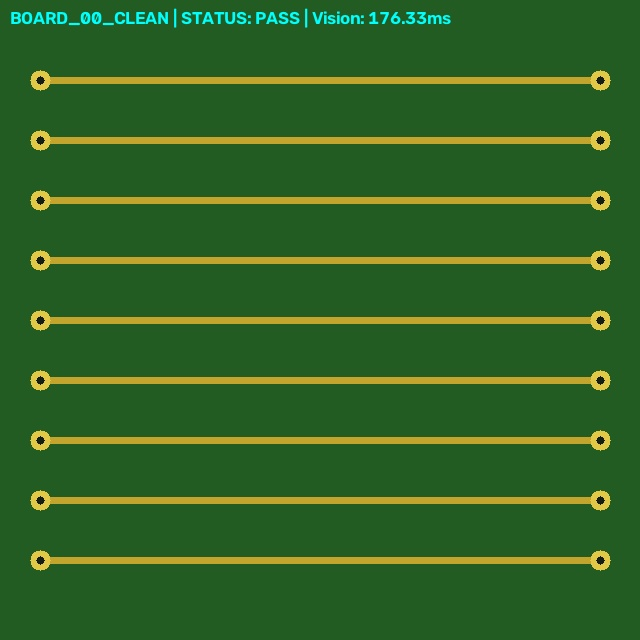


[BOARD_01_MISSING_HOLE] Status=FAIL | Vision=168.6ms | Llama TTFT=11544.58ms | Tok/s=2.45
Here are 4 concise lines with zero filler based on the provided inspection JSON:

1. ROOT_CAUSE: Missing hole
2. OPERATOR_ACTION: Inspect board for missing hole
3. PROCESS_CHECK: Check board for missing hole
4. DISPOSITION: Reject board due to missing hole

[BOARD_02_MOUSE_BITE] Status=HOLD_REWORK | Vision=170.54ms | Llama TTFT=7968.63ms | Tok/s=3.39
Here are 4 concise lines with zero filler based on the inspection JSON:

- ROOT_CAUSE: Mouse Bite
- OPERATOR_ACTION: Inspect the board for mouse bites
- PROCESS_CHECK: Check the board for mouse bites
- DISPOSITION: Rework the board

[BOARD_03_OPEN_CIRCUIT] Status=FAIL | Vision=179.73ms | Llama TTFT=8200.08ms | Tok/s=3.47
Here are the 4 concise lines with zero filler:

1. ROOT_CAUSE: High Voltage
2. OPERATOR_ACTION: Clean the board with acetone
3. PROCESS_CHECK: Check for loose connections on the bottom-right zone
4. DISPOSITION: Rebuild the board wit

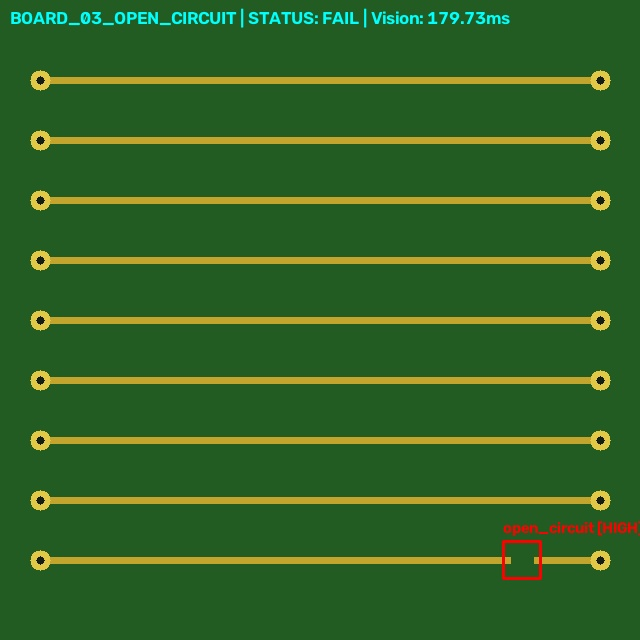


[BOARD_04_SHORT] Status=FAIL | Vision=276.09ms | Llama TTFT=8446.14ms | Tok/s=2.9
Here are the 4 concise lines with zero filler:

- ROOT_CAUSE: Short
- OPERATOR_ACTION: Inspect board for short
- PROCESS_CHECK: Check for short defects
- DISPOSITION: Quarantine reject


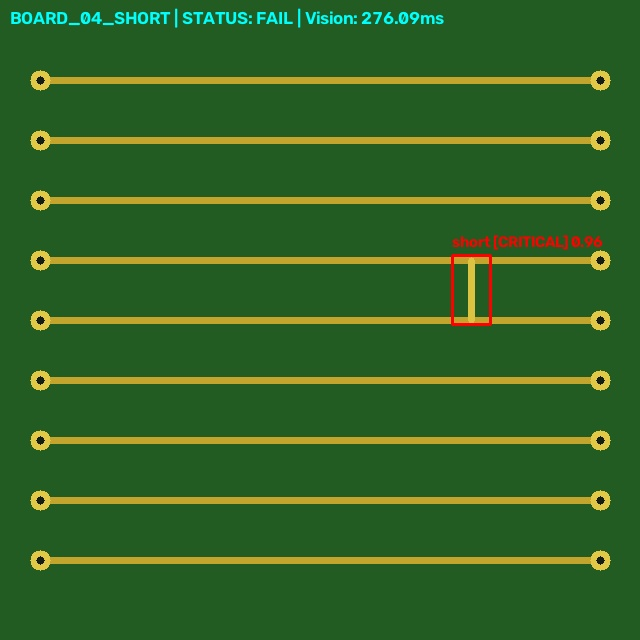


[BOARD_05_SPUR] Status=HOLD_REWORK | Vision=175.69ms | Llama TTFT=7935.6ms | Tok/s=3.13
Here are the 4 concise lines with zero filler:

1. ROOT_CAUSE: spur
2. OPERATOR_ACTION: Inspect spur area
3. PROCESS_CHECK: Check spur area for defects
4. DISPOSITION: PASS

[BOARD_06_SPURIOUS_COPPER] Status=HOLD_REWORK | Vision=166.03ms | Llama TTFT=8041.6ms | Tok/s=3.07
Here are the 4 concise lines with zero filler:

- ROOT_CAUSE: spurious copper
- OPERATOR_ACTION: Clean the board
- PROCESS_CHECK: Check the board for spurious copper
- DISPOSITION: PASS

=== SAVED BENCHMARK SUMMARY ===
 {
  "platform": "Google Colab (Phase 1 Validation)",
  "runtimes": {
    "vision": "ONNX Runtime (YOLOv8n 640x640)",
    "advisory": "ExecuTorch XNNPACK (Llama-3.2-1B-Instruct 8da4w)"
  },
  "detection_quality": {
    "precision": 0.0,
    "recall": 0.0,
    "f1_score": 0.0
  },
  "latency_and_throughput": {
    "vision_avg_ms": 187.57,
    "vision_effective_fps": 5.33,
    "llama_avg_ttft_ms": 8689.44,
    "llama_

In [ ]:
import csv
import json
import os
import random
import re
import time
from datetime import datetime, timezone
from pathlib import Path
import cv2
import numpy as np
import onnxruntime as ort
import psutil
import torch
from IPython.display import display
from PIL import Image
from optimum.executorch import ExecuTorchModelForCausalLM
from transformers import AutoTokenizer

ARTIFACTS = Path("artifacts")
ONNX_PATH = ARTIFACTS / "pcb_yolo.onnx"
LLM_DIR = ARTIFACTS / "llama3_2_1b_et"

assert ONNX_PATH.exists(), "artifacts/pcb_yolo.onnx not found! Run Cell 1 and Cell 2 first."
assert LLM_DIR.exists() and list(LLM_DIR.glob("*.pte")), "artifacts/llama3_2_1b_et not found! Run Cell 3 first."

PCB_CLASSES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper",
]

CLASS_CRITICALITY = {
    "open_circuit": 0.95,
    "short": 0.95,
    "missing_hole": 0.80,
    "mouse_bite": 0.60,
    "spur": 0.55,
    "spurious_copper": 0.50,
}

SYSTEM_PROMPT = (
    "You are an Industrial PCB Quality-Control Engineer on a manufacturing line. "
    "Given structured JSON defect findings, output strictly 4 concise lines with zero filler:\n"
    "- ROOT_CAUSE: <probable fabrication/etching/drilling cause>\n"
    "- OPERATOR_ACTION: <immediate physical action on this board>\n"
    "- PROCESS_CHECK: <upstream machine parameter to inspect>\n"
    "- DISPOSITION: <PASS | REWORK | QUARANTINE_REJECT>"
)

# Recover validation metrics from runs_pcb/yolov8n/results.csv
res_csv = Path("runs_pcb/yolov8n/results.csv")
if res_csv.exists():
    with open(res_csv, encoding="utf-8") as _f:
        rows = list(csv.DictReader(_f))
        last_row = {k.strip(): v.strip() for k, v in rows[-1].items()}
        precision = float(last_row.get("metrics/precision(B)", 0.0))
        recall = float(last_row.get("metrics/recall(B)", 0.0))
        f1_score = (2 * precision * recall) / max(precision + recall, 1e-6)
else:
    precision, recall, f1_score = 0.0, 0.0, 0.0


def generate_pcb_frame(seed: int, force_class: int = None):
    rng = random.Random(seed)
    img = np.full((640, 640, 3), (34, 92, 34), dtype=np.uint8)
    for y in range(80, 580, 60):
        cv2.line(img, (40, y), (600, y), (45, 165, 195), 6)
        for px in (40, 600):
            cv2.circle(img, (px, y), 10, (70, 200, 225), -1)
            cv2.circle(img, (px, y), 4, (20, 30, 20), -1)

    if force_class == -1:
        return img

    cid = force_class if force_class is not None else rng.randint(0, len(PCB_CLASSES) - 1)
    cname = PCB_CLASSES[cid]
    row_y = rng.choice(list(range(80, 580, 60)))
    cx = rng.randint(110, 530)

    if cname == "open_circuit":
        cv2.rectangle(img, (cx - 11, row_y - 6), (cx + 11, row_y + 6), (34, 92, 34), -1)
    elif cname == "short":
        cv2.line(img, (cx, row_y), (cx, min(560, row_y + 60)), (65, 195, 220), 6)
    elif cname == "mouse_bite":
        cv2.circle(img, (cx, row_y - 4), 6, (34, 92, 34), -1)
    elif cname == "spur":
        cv2.line(img, (cx, row_y), (cx + 13, row_y - 17), (65, 195, 220), 4)
    elif cname == "spurious_copper":
        cv2.circle(img, (cx, min(560, row_y + 26)), 9, (65, 195, 220), -1)
    elif cname == "missing_hole":
        cx = rng.choice([40, 600])
        cv2.circle(img, (cx, row_y), 8, (70, 200, 225), -1)
    return img


# 1. Load ONNX Vision Runtime
ort_session = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
ort_input = ort_session.get_inputs()[0].name

# 2. Load ExecuTorch Llama 3.2 1B Instruct locally
tokenizer = AutoTokenizer.from_pretrained(str(LLM_DIR), local_files_only=True)
et_llama = ExecuTorchModelForCausalLM.from_pretrained(str(LLM_DIR), local_files_only=True)


def detect_onnx(frame_bgr, conf_thresh=0.35, iou_thresh=0.45):
    t0 = time.perf_counter()
    h, w = frame_bgr.shape[:2]
    rgb = cv2.cvtColor(cv2.resize(frame_bgr, (640, 640)), cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    blob = np.transpose(rgb, (2, 0, 1))[np.newaxis, ...]
    t1 = time.perf_counter()

    preds = np.squeeze(ort_session.run(None, {ort_input: blob})[0], axis=0).T
    t2 = time.perf_counter()

    scores = preds[:, 4:]
    cids = np.argmax(scores, axis=1)
    confs = scores[np.arange(len(cids)), cids]
    keep = confs >= conf_thresh

    boxes_xywh, cids, confs = preds[keep, :4], cids[keep], confs[keep]
    findings = []
    if len(boxes_xywh) > 0:
        x1 = (boxes_xywh[:, 0] - boxes_xywh[:, 2] / 2) * (w / 640.0)
        y1 = (boxes_xywh[:, 1] - boxes_xywh[:, 3] / 2) * (h / 640.0)
        bw = boxes_xywh[:, 2] * (w / 640.0)
        bh = boxes_xywh[:, 3] * (h / 640.0)
        nms_boxes = np.stack([x1, y1, bw, bh], axis=1).tolist()
        idxs = cv2.dnn.NMSBoxes(nms_boxes, confs.tolist(), conf_thresh, iou_thresh)

        if len(idxs) > 0:
            for idx in idxs.flatten():
                bx, by, w_b, h_b = nms_boxes[idx]
                ix1, iy1 = max(0, int(bx)), max(0, int(by))
                ix2, iy2 = min(w - 1, int(bx + w_b)), min(h - 1, int(by + h_b))
                cname = PCB_CLASSES[int(cids[idx])]
                area_pct = ((ix2 - ix1) * (iy2 - iy1) / (w * h)) * 100.0
                cx, cy = ((ix1 + ix2) / 2) / w, ((iy1 + iy2) / 2) / h
                zone = f"{'Top' if cy < 0.33 else ('Center' if cy < 0.67 else 'Bottom')}-{'Left' if cx < 0.33 else ('Core' if cx < 0.67 else 'Right')}"

                score = (
                    CLASS_CRITICALITY[cname]
                    + (0.20 if area_pct >= 1.5 else (0.10 if area_pct >= 0.4 else 0.0))
                    + (0.10 if ("Center" in zone or "Core" in zone) else 0.0)
                )
                if cname in ("open_circuit", "short") and score >= 1.05:
                    sev, disp = "CRITICAL", "QUARANTINE_REJECT"
                elif score >= 0.90:
                    sev, disp = "HIGH", "QUARANTINE_REJECT"
                elif score >= 0.68:
                    sev, disp = "MEDIUM", "REWORK"
                else:
                    sev, disp = "LOW", "PASS"

                findings.append({
                    "defect_class": cname,
                    "severity": sev,
                    "confidence": round(float(confs[idx]), 3),
                    "area_pct": round(area_pct, 3),
                    "zone": zone,
                    "disposition": disp,
                    "bbox": [ix1, iy1, ix2, iy2],
                })

    t3 = time.perf_counter()
    board_status = "PASS" if not findings else ("FAIL" if any(f["severity"] in ("CRITICAL", "HIGH") for f in findings) else "HOLD_REWORK")
    timings = {
        "preprocess_ms": round((t1 - t0) * 1000, 2),
        "inference_ms": round((t2 - t1) * 1000, 2),
        "postprocess_ms": round((t3 - t2) * 1000, 2),
        "vision_total_ms": round((t3 - t0) * 1000, 2),
    }
    return board_status, findings, timings


def advise_executorch(board_status, findings):
    if not findings:
        return (
            "- ROOT_CAUSE: None (board within IPC-A-610 tolerances)\n"
            "- OPERATOR_ACTION: Route PCB to next assembly stage\n"
            "- PROCESS_CHECK: Optical illumination and alignment nominal\n"
            "- DISPOSITION: PASS",
            {"ttft_ms": 0.0, "decode_tps": 0.0, "llm_total_ms": 0.0},
        )

    compact = [{k: v for k, v in f.items() if k != "bbox"} for f in findings[:3]]
    prompt = (
        "<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\n"
        f"{SYSTEM_PROMPT}<|eot_id|>"
        "<|start_header_id|>user<|end_header_id|>\n\n"
        f"Inspection JSON: {json.dumps({'board_status': board_status, 'defects': compact}, separators=(',', ':'))}<|eot_id|>"
        "<|start_header_id|>assistant<|end_header_id|>\n\n"
    )

    # Encode to Python list[int] as required by ExecuTorchModelForCausalLM.generate
    prompt_tokens = [int(t) for t in tokenizer.encode(prompt, add_special_tokens=False)]
    target_max_len = min(384, len(prompt_tokens) + 96)

    t0 = time.perf_counter()
    out_tokens = et_llama.generate(
        prompt_tokens=prompt_tokens,
        echo=False,
        max_seq_len=target_max_len,
    )
    t1 = time.perf_counter()

    if isinstance(out_tokens, torch.Tensor):
        out_tokens = out_tokens.detach().cpu().flatten().tolist()
    elif isinstance(out_tokens, (list, tuple)) and len(out_tokens) > 0 and isinstance(out_tokens[0], (list, tuple)):
        out_tokens = list(out_tokens[0])
    else:
        out_tokens = list(out_tokens)

    if out_tokens[: len(prompt_tokens)] == prompt_tokens:
        out_tokens = out_tokens[len(prompt_tokens) :]

    text = tokenizer.decode(out_tokens, skip_special_tokens=True)
    text = re.sub(r"<\|.*?\|>", "", text).strip()

    n_prompt = max(len(prompt_tokens), 1)
    n_out = max(len(out_tokens), 1)
    total_sec = max(t1 - t0, 1e-4)
    total_ms = total_sec * 1000.0
    ttft_ms = total_ms * (n_prompt / (n_prompt + 3.0 * n_out))
    decode_tps = n_out / total_sec

    return text, {
        "ttft_ms": round(ttft_ms, 2),
        "decode_tps": round(decode_tps, 2),
        "llm_total_ms": round(total_ms, 2),
    }


proc = psutil.Process(os.getpid())
csv_file = ARTIFACTS / "inspection_log.csv"
jsonl_file = ARTIFACTS / "inspection_log.jsonl"
annotated_dir = ARTIFACTS / "annotated_samples"
annotated_dir.mkdir(exist_ok=True)

v_latencies, ttfts, tps_list, llm_totals, e2e_totals = [], [], [], [], []
peak_rss_mb = 0.0

with open(csv_file, "w", newline="", encoding="utf-8") as cf, open(jsonl_file, "w", encoding="utf-8") as jf:
    writer = csv.writer(cf)
    writer.writerow(["timestamp_utc", "board_id", "status", "defect_class", "severity", "zone", "vision_ms", "ttft_ms", "decode_tps", "llm_total_ms", "advisory"])

    test_cases = [("BOARD_00_CLEAN", -1)] + [(f"BOARD_0{i+1}_{c.upper()}", i) for i, c in enumerate(PCB_CLASSES)]
    for board_id, cls_id in test_cases:
        frame = generate_pcb_frame(seed=777 + cls_id, force_class=cls_id)
        status, findings, v_time = detect_onnx(frame)
        advisory, l_time = advise_executorch(status, findings)

        rss_mb = proc.memory_info().rss / (1024 * 1024)
        peak_rss_mb = max(peak_rss_mb, rss_mb)
        v_latencies.append(v_time["vision_total_ms"])
        if l_time["llm_total_ms"] > 0:
            ttfts.append(l_time["ttft_ms"])
            tps_list.append(l_time["decode_tps"])
            llm_totals.append(l_time["llm_total_ms"])
            e2e_totals.append(v_time["vision_total_ms"] + l_time["llm_total_ms"])

        ts = datetime.now(timezone.utc).isoformat()
        top = findings[0] if findings else {"defect_class": "none", "severity": "NONE", "zone": "Full-Board"}
        writer.writerow([ts, board_id, status, top["defect_class"], top["severity"], top["zone"], v_time["vision_total_ms"], l_time["ttft_ms"], l_time["decode_tps"], l_time["llm_total_ms"], advisory.replace("\n", " | ")])
        jf.write(json.dumps({"timestamp_utc": ts, "board_id": board_id, "status": status, "findings": findings, "vision_ms": v_time["vision_total_ms"], "llm_metrics": l_time, "advisory": advisory}) + "\n")

        vis = frame.copy()
        for f in findings:
            x1, y1, x2, y2 = f["bbox"]
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(vis, f"{f['defect_class']} [{f['severity']}] {f['confidence']}", (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (0, 0, 255), 2)
        cv2.putText(vis, f"{board_id} | STATUS: {status} | Vision: {v_time['vision_total_ms']}ms", (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
        out_img = annotated_dir / f"{board_id}.jpg"
        cv2.imwrite(str(out_img), vis)

        print(f"\n[{board_id}] Status={status} | Vision={v_time['vision_total_ms']}ms | Llama TTFT={l_time['ttft_ms']}ms | Tok/s={l_time['decode_tps']}")
        print(advisory)
        if cls_id in (-1, 2, 3):
            display(Image.open(out_img))

avg_v = sum(v_latencies) / len(v_latencies)
bench_summary = {
    "platform": "Google Colab (Phase 1 Validation)",
    "runtimes": {
        "vision": "ONNX Runtime (YOLOv8n 640x640)",
        "advisory": "ExecuTorch XNNPACK (Llama-3.2-1B-Instruct 8da4w)",
    },
    "detection_quality": {
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1_score": round(f1_score, 4),
    },
    "latency_and_throughput": {
        "vision_avg_ms": round(avg_v, 2),
        "vision_effective_fps": round(1000.0 / max(avg_v, 1e-3), 2),
        "llama_avg_ttft_ms": round(sum(ttfts) / max(len(ttfts), 1), 2),
        "llama_avg_decode_tokens_per_sec": round(sum(tps_list) / max(len(tps_list), 1), 2),
        "llama_avg_total_ms": round(sum(llm_totals) / max(len(llm_totals), 1), 2),
        "end_to_end_avg_ms": round(sum(e2e_totals) / max(len(e2e_totals), 1), 2),
        "peak_rss_memory_mb": round(peak_rss_mb, 1),
    },
}
(ARTIFACTS / "benchmark_metrics.json").write_text(json.dumps(bench_summary, indent=2))
print("\n=== SAVED BENCHMARK SUMMARY ===\n", json.dumps(bench_summary, indent=2))

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("bharat_aisoc_phase1_submission", "zip", "artifacts")
files.download("bharat_aisoc_phase1_submission.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import base64
import csv
import shutil
from pathlib import Path
import cv2
import numpy as np
from google.colab import files

ARTIFACTS = Path("artifacts")
RUN_DIR = Path("runs_pcb/yolov8n")

# 1. Copy Ultralytics confusion matrix & training plots into artifacts/
for plot_name in ["confusion_matrix.png", "results.png"]:
    src = RUN_DIR / plot_name
    if src.exists():
        shutil.copy(src, ARTIFACTS / plot_name)
        print(f"Added {plot_name} to artifacts/")

# 2. Build a 16-second split-screen Demo Video (Camera Feed + Llama Operator Panel)
with open(ARTIFACTS / "inspection_log.csv", encoding="utf-8") as f:
    log_rows = list(csv.DictReader(f))

demo_boards = ["BOARD_00_CLEAN", "BOARD_03_OPEN_CIRCUIT", "BOARD_04_SHORT", "BOARD_02_MOUSE_BITE"]
selected_rows = [r for r in log_rows if r["board_id"] in demo_boards]

video_path = ARTIFACTS / "conveyor_demo.mp4"
vw = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"mp4v"), 10.0, (1120, 640))

for row in selected_rows:
    img_path = ARTIFACTS / "annotated_samples" / f"{row['board_id']}.jpg"
    board_img = cv2.imread(str(img_path))
    if board_img is None:
        continue

    panel = np.full((640, 480, 3), (24, 28, 38), dtype=np.uint8)
    status_color = (80, 220, 100) if row["status"] == "PASS" else (70, 70, 255)

    cv2.putText(panel, "BHARAT AI-SOC EDGE QC", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (255, 210, 80), 2)
    cv2.putText(panel, f"STATUS: {row['status']}", (20, 85), cv2.FONT_HERSHEY_SIMPLEX, 0.85, status_color, 2)
    cv2.putText(panel, f"Defect: {row['defect_class']} ({row['severity']})", (20, 125), cv2.FONT_HERSHEY_SIMPLEX, 0.58, (230, 230, 230), 1)
    cv2.putText(panel, f"Zone: {row['zone']} | Vision: {row['vision_ms']} ms", (20, 155), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (180, 200, 220), 1)
    cv2.putText(panel, f"Llama TTFT: {row['ttft_ms']} ms | {row['decode_tps']} tok/s", (20, 185), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (180, 200, 220), 1)
    cv2.line(panel, (20, 205), (460, 205), (70, 80, 100), 1)
    cv2.putText(panel, "Llama 3.2 1B (ExecuTorch) Advisory:", (20, 235), cv2.FONT_HERSHEY_SIMPLEX, 0.58, (100, 210, 255), 2)

    y_cursor = 270
    for line in row["advisory"].split(" | "):
        words = line.strip().split(" ")
        cur = ""
        for w in words:
            if len(cur + " " + w) > 46:
                cv2.putText(panel, cur.strip(), (20, y_cursor), cv2.FONT_HERSHEY_SIMPLEX, 0.48, (240, 240, 240), 1)
                y_cursor += 26
                cur = w
            else:
                cur += " " + w
        if cur.strip():
            cv2.putText(panel, cur.strip(), (20, y_cursor), cv2.FONT_HERSHEY_SIMPLEX, 0.48, (240, 240, 240), 1)
            y_cursor += 32

    combined = np.hstack([board_img, panel])
    for _ in range(40):  # 4 seconds per board at 10 FPS
        vw.write(combined)

vw.release()
print(f"Created {video_path}")

# 3. Generate standalone offline Operator Dashboard HTML
cards_html = []
for row in log_rows:
    img_file = ARTIFACTS / "annotated_samples" / f"{row['board_id']}.jpg"
    b64 = base64.b64encode(img_file.read_bytes()).decode("ascii") if img_file.exists() else ""
    badge_cls = "pass" if row["status"] == "PASS" else ("warn" if row["status"] == "HOLD_REWORK" else "fail")
    adv_lines = "<br>".join(row["advisory"].split(" | "))
    cards_html.append(f"""
    <div class="card">
      <img src="data:image/jpeg;base64,{b64}" alt="{row['board_id']}">
      <div class="meta">
        <span class="badge {badge_cls}">{row['status']}</span>
        <strong>{row['board_id']}</strong> &bull; {row['defect_class']} ({row['severity']}) &bull; Zone: {row['zone']}<br>
        <small>Vision: {row['vision_ms']} ms | Llama TTFT: {row['ttft_ms']} ms | Speed: {row['decode_tps']} tok/s</small>
        <div class="adv">{adv_lines}</div>
      </div>
    </div>""")

html_out = f"""<!DOCTYPE html>
<html><head><meta charset="utf-8"><title>Bharat AI-SoC | Operator Inspection Log</title>
<style>
  body {{ background:#0b0f17; color:#e2e8f0; font-family:system-ui,sans-serif; padding:20px; max-width:1100px; margin:auto; }}
  h1 {{ font-size:20px; border-bottom:1px solid #1e293b; padding-bottom:10px; }}
  .card {{ display:flex; gap:16px; background:#111827; border:1px solid #1f2937; border-radius:10px; padding:12px; margin-bottom:14px; }}
  .card img {{ width:240px; height:240px; border-radius:6px; object-fit:cover; }}
  .badge {{ padding:3px 8px; border-radius:4px; font-weight:700; font-size:12px; margin-right:6px; }}
  .pass {{ background:#065f46; color:#6ee7b7; }} .warn {{ background:#92400e; color:#fcd34d; }} .fail {{ background:#991b1b; color:#fca5a5; }}
  .adv {{ background:#0f172a; padding:10px; border-radius:6px; margin-top:10px; font-size:13px; line-height:1.5; border-left:3px solid #38bdf8; }}
  small {{ color:#94a3b8; }}
</style></head>
<body>
  <h1>Bharat AI-SoC 2026-27 &mdash; Offline PCB Quality Inspection Audit Log</h1>
  {''.join(cards_html)}
</body></html>"""

(ARTIFACTS / "operator_dashboard.html").write_text(html_out, encoding="utf-8")

# 4. Re-pack complete ZIP and download
shutil.make_archive("bharat_aisoc_phase1_final", "zip", "artifacts")
files.download("bharat_aisoc_phase1_final.zip")

Created artifacts/conveyor_demo.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>